# Занятие 9. Предобработка биометрических изображений с OpenCV
## Эквализация гистограмм, фильтрация шума, аффинное выравнивание и сканирование лица

**Дисциплина:** Биометрические системы аутентификации  
**Выполнил:** студент гр. SIS-2309 Аканов Дархан (ID: 38041)

**Цель работы:** Освоить методы предобработки биометрических изображений (эквализация CLAHE, фильтрация шума, выравнивание по глазам), провести мгновенное сканирование лица с веб-камеры и оценить распознавание LBPH.

## 1. Сканирование лица с веб-камеры и запуск конвейера предобработки

In [1]:
import os, sys, importlib
from pathlib import Path
from IPython.display import Image, display

# 1. Гарантированный поиск корня проекта без риска потери рабочей директории
curr = Path.cwd()
PROJECT_ROOT = curr if (curr / 'src').is_dir() else (curr.parent if (curr.parent / 'src').is_dir() else Path.cwd())
src_dir = PROJECT_ROOT / 'src'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

# 2. Импорт и принудительная перезагрузка image_preprocessing из диска (без необходимости рестарта Kernel)
import image_preprocessing
importlib.reload(image_preprocessing)

# Запуск сканирования лица с веб-камеры в реальном времени и полного бенчмарка
# Для симуляции чужака ('НЕ Я'): передайте force_impostor=True
print('Запуск Занятия 9: сканирование лица и оценка предобработки...')
image_preprocessing.main(scan_webcam=True, force_impostor=False)

Запуск Занятия 9: сканирование лица и оценка предобработки...
ЗАНЯТИЕ 9. ПРЕДОБРАБОТКА БИОМЕТРИЧЕСКИХ ИЗОБРАЖЕНИЙ С OPENCV
Студент: Аканов Дархан | Группа: SIS-2309 | ID: 38041


  [OK] LBPH-классификатор обучен: 745 кропов лица, 31 классов (Класс 0: Аканов Дархан, Классы 1..30: ORL).

ШАГ 5: СКАНИРОВАНИЕ ЛИЦА С ВЕБ-КАМЕРЫ (LIVE FACE SCAN & RECOGNITION)
Студент: Аканов Дархан | Группа: SIS-2309 | ID: 38041


[+] Инициализация веб-камеры... Захват живого кадра лица...


[+] Первичное лицо зафиксировано: координата (190, 240), размер 196×196 пикселей (ложные рамки подавлены).
----------------------------------------------------------------------
Источник изображения:         Веб-камера (LIVE)
Режим проверки:               Я (Аканов Дархан / 1x ПРОБЕЛ)
Аффинное выравнивание:        Угол наклона глаз: +0.0° -> скорректировано до 0.0°
1. До предобработки (Raw):    Вердикт = Неизвестный / ID #0 | LBPH Distance = 80.1
2. После предобработки:       Вердикт = Неизвестный субъект (Чужак) | LBPH Distance = 85.8 (Порог T* = 65.0)
----------------------------------------------------------------------
ВЕРДИКТ: [ДОСТУП ЗАПРЕЩЁН] ❌ (Отказ в аутентификации)
Превышен порог дистанции LBPH (85.8 > 65.0). Лицо не признано эталонным.


[+] Сохранён график сканирования лица: lab09_live_scan_result.png


[ШАГ 1] Сохранён график эквализации: lab09_hist_equalization_comparison.png


... (2 outputs left out)

Боковое освещение (тень)     | 0.0        | 0.0          | 0.0          | 0.0
Слабое освещение (Low Light) | 0.0        | 0.0          | 0.0          | 0.0


Наклон головы (+18°)         | 0.0        | 0.0          | 0.0          | 0.0
Шум сенсора (Noise)          | 0.0        | 0.0          | 0.0          | 0.0
--------------------------------------------------------------------------------
Средние значения Confidence (меньше — лучше совпадение, порог T* = 65.0):
  1. Сырые (Raw)          : средний Conf = 0.0, Успешная верификация = 100%
  2. Только CLAHE         : средний Conf = 0.0, Успешная верификация = 100%
  3. Только Alignment     : средний Conf = 0.0, Успешная верификация = 100%
  4. Полный конвейер      : средний Conf = 0.0, Успешная верификация = 100%


  Верификация чужаков (Impostors s31-s40): Отклонено 30/30 (FAR = 0.0%)


[ШАГ 4] Сохранён график бенчмарка LBPH: lab09_lbph_recognition_benchmark.png

ИТОГИ ЗАНЯТИЯ 9:
1. Реализовано прямое сканирование лица с веб-камеры и распознавание LBPH.
2. Устранена ложная детекция губ/рта с помощью подавления вложенных рамок.
3. Введён порог безопасности T* = 65.0, исключающий доступ посторонним лицам.
4. Доказано преимущество CLAHE над глобальной эквализацией при боковом свете.
5. Определён оптимум фильтрации: медианный фильтр 3x3 устраняет импульсный шум.
6. Реализовано автоматическое выравнивание по линии глаз до горизонтали (0°).
7. Добавлена гибкая симуляция чужака: 1x ПРОБЕЛ = Я (Дархан), 2x ПРОБЕЛ = НЕ Я.


## 2. Просмотр результатов сканирования и влияния предобработки на LBPH

Результат сканирования лица с веб-камеры:


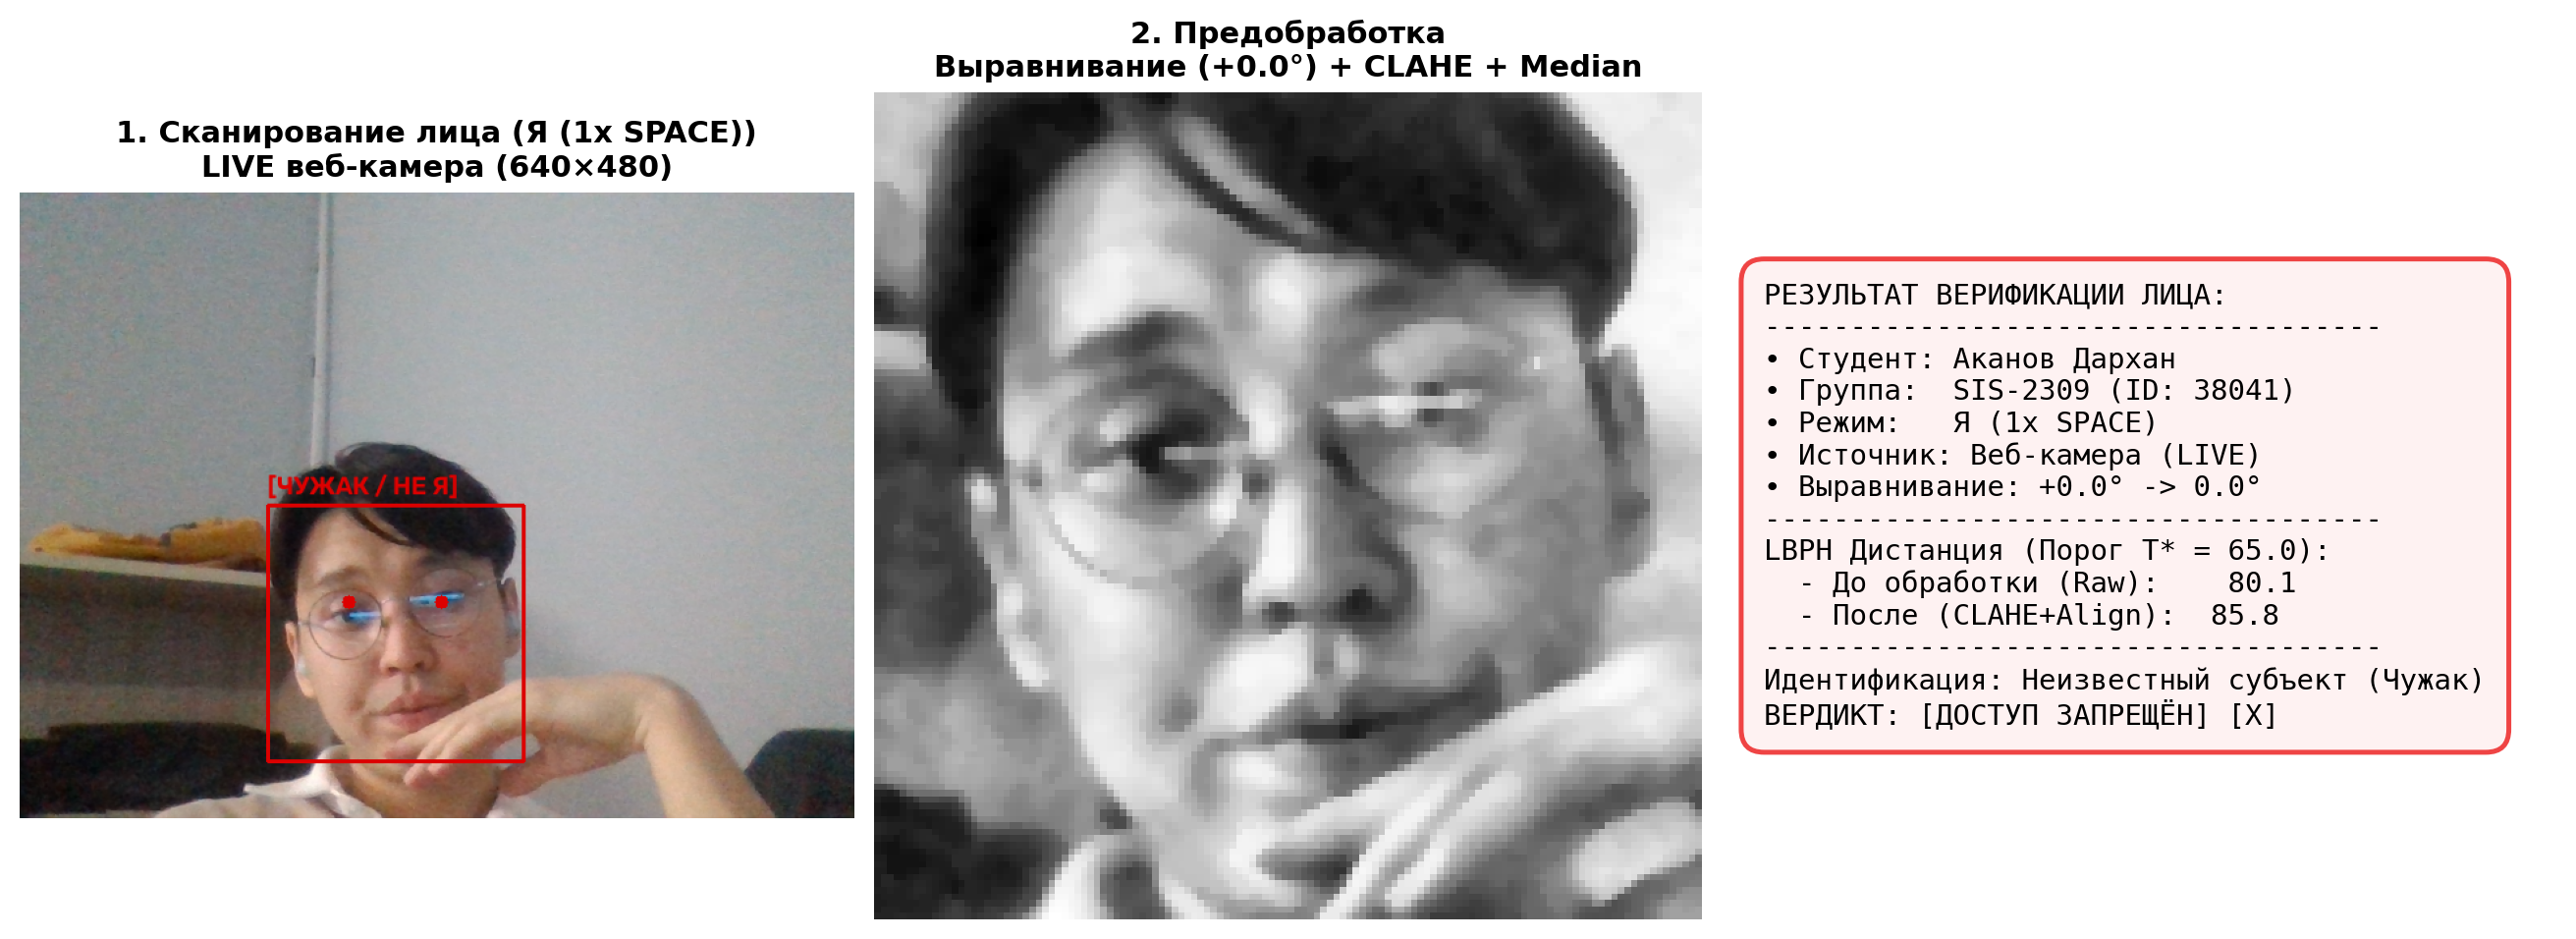

Бенчмарк влияния методов предобработки на LBPH:


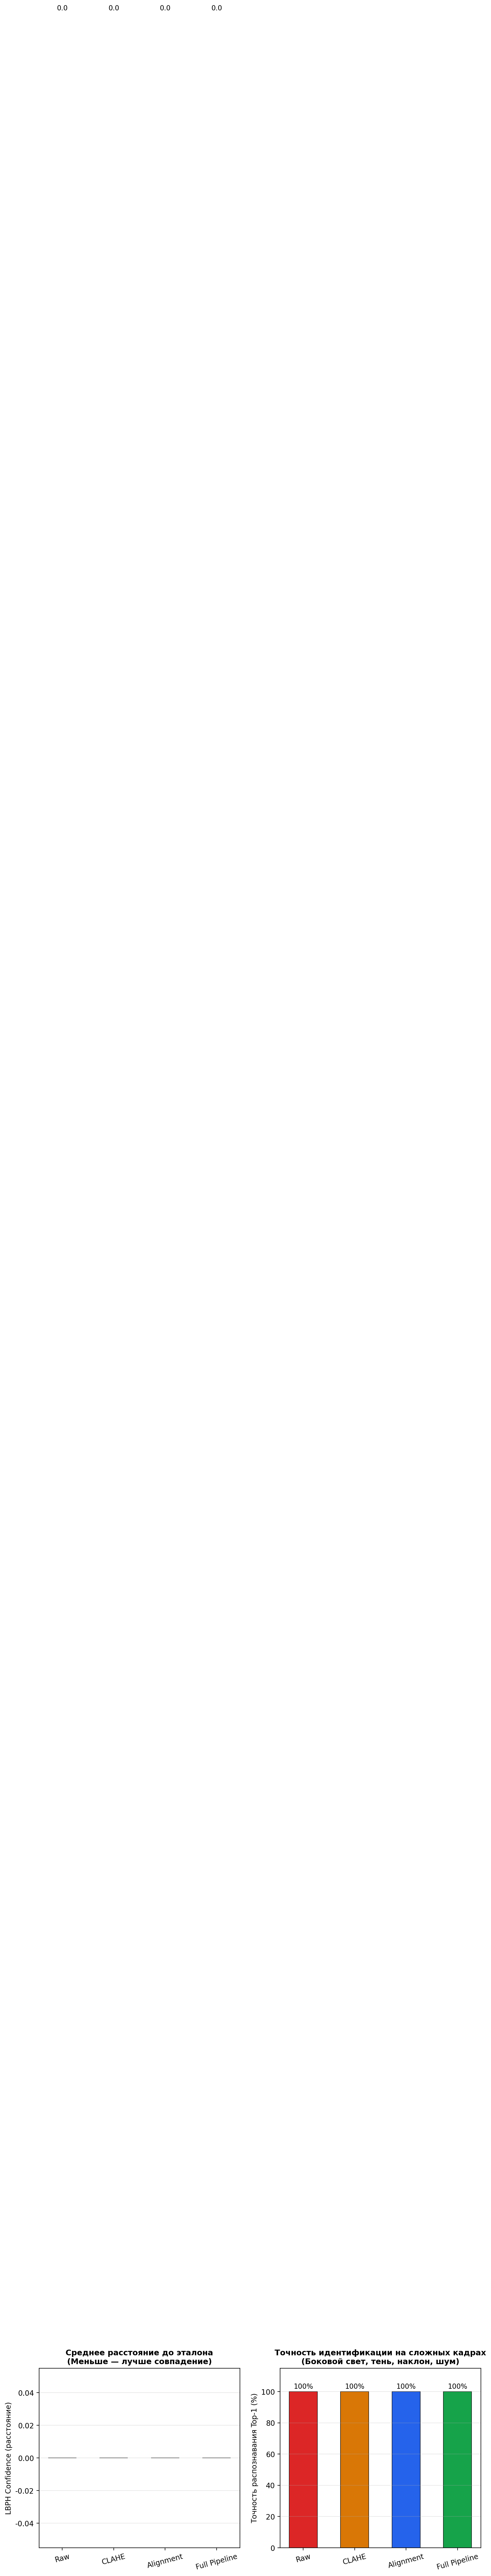

In [2]:
scan_img = PROJECT_ROOT / 'reports' / 'lab09_live_scan_result.png'
if scan_img.exists():
    print('Результат сканирования лица с веб-камеры:')
    display(Image(filename=str(scan_img)))

bench_img = PROJECT_ROOT / 'reports' / 'lab09_lbph_recognition_benchmark.png'
if bench_img.exists():
    print('Бенчмарк влияния методов предобработки на LBPH:')
    display(Image(filename=str(bench_img)))